# Задача 2. Источник света

Класс `Source` с выходом $Y = 10\,000$ фотонов/МэВ.

- **Число фотонов** линейно по энергии: $n = \mathrm{round}(YE)$. Случайным оно станет в задаче 5, поэтому здесь и в задачах 3, 4 метод вызывается с `fluctuate=False`.
- **Изотропия**: $d\Omega = d\phi\, d\cos\theta$, поэтому $\phi \sim U(0, 2\pi)$, $\cos\theta \sim U(-1, 1)$. Направления — массив формы `(n, 3)`, как и координаты ФЭУ в `Detector`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from source import Source

src = Source(Y=10_000, rng=1)
d = src.directions(E=1.0, fluctuate=False)
print(d.shape)
print("нормы:", np.linalg.norm(d, axis=1)[:5])

(10000, 3)
нормы: [1. 1. 1. 1. 1.]


## Линейность выхода

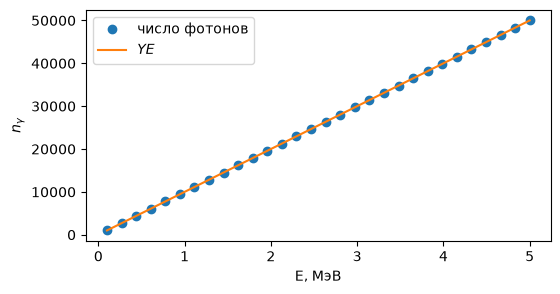

In [2]:
E = np.linspace(0.1, 5, 30)
n = np.array([len(src.directions(e, fluctuate=False)) for e in E])
plt.figure(figsize=(6, 3))
plt.plot(E, n, 'o', label='число фотонов')
plt.plot(E, src.Y*E, label='$YE$')
plt.xlabel('E, МэВ'); plt.ylabel(r'$n_\gamma$'); plt.legend(); plt.show()

## Проверка изотропии

Для изотропного распределения $\cos\theta$ и $\phi$ равномерны, $\langle n_i\rangle = 0$, $\langle n_i^2\rangle = 1/3$.

<n>   = [-0.0001  0.0008  0.0009]
<n^2> = [0.3334 0.3334 0.3332]


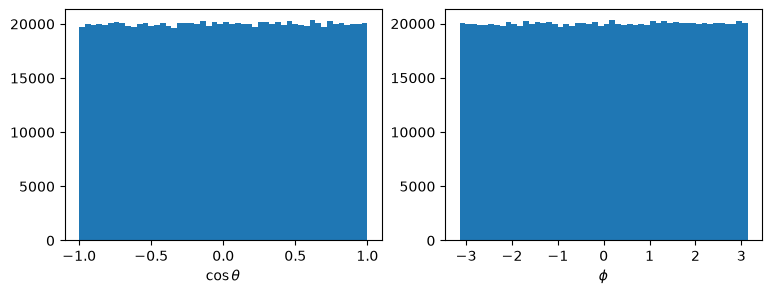

In [3]:
d = src.directions(E=100.0, fluctuate=False)   # 1e6 фотонов
print("<n>   =", d.mean(axis=0).round(4))
print("<n^2> =", (d**2).mean(axis=0).round(4))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(d[:, 2], bins=50); ax[0].set_xlabel(r'$\cos\theta$')
ax[1].hist(np.arctan2(d[:, 1], d[:, 0]), bins=50); ax[1].set_xlabel(r'$\phi$')
plt.show()

Направления 300 фотонов в k3d. Интерактивный виджет k3d виден только при запуске ноутбука: GitHub и другие просмотрщики его не показывают.

In [4]:
import k3d
plot = k3d.plot()
d3 = src.directions(0.03, fluctuate=False).astype(np.float32)   # 300 фотонов
plot += k3d.vectors(np.zeros_like(d3), d3, head_size=0.5)
plot.display()

**Вывод.** Метод `Source.directions(E)` возвращает массив единичных векторов `(n, 3)`. Число фотонов линейно по энергии ($n = YE$), а $\langle n_i\rangle \approx 0$ и $\langle n_i^2\rangle \approx 1/3$ подтверждают изотропию.